# Assignment 3: EDA and Metric Analysis

Full Ukrainian raw corpus and processed labels, full test, and the provided in-domain sample. The Russian auxiliary corpus is not included. Read `reports/EDA_AND_METRIC_ANALYSIS.md` for interpretation and limitations. Saved outputs below were produced from the measured JSON/CSV artifacts; full-data processing is reproducible in the optional final cell.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import display, Image
BASE = Path.cwd() if (Path.cwd() / 'reports/eda_summary.json').exists() else Path.cwd() / 'assignment3'
BASE = BASE.resolve()
sys.path.insert(0, str(BASE))
summary = json.loads((BASE / 'reports/eda_summary.json').read_text(encoding='utf-8'))
overview = pd.read_csv(BASE / 'reports/dataset_overview.csv')
display(overview)

,dataset,rows,missing_text,median_chars,p95_chars,median_tokens,duplicates,loc_mentions,empty_loc_fraction
0,uk_train_all,1010000,0,91.0,197.0,13.0,2454,345114.0,0.768890
1,labeling_sample,26,0,217.5,814.0,31.5,0,32.0,0.384615
2,test,477,0,264.0,1123.2,36.0,0,NaN,NaN
3,uk_fit,1000000,0,91.0,197.0,13.0,2402,341810.0,0.768882
4,uk_valid,10000,0,92.0,199.0,13.0,0,3304.0,0.769700


## Distribution and domain shift

Test `locations` are placeholders. Character/script indicators are descriptive and are not language labels. Token lengths in the table are whitespace-based.

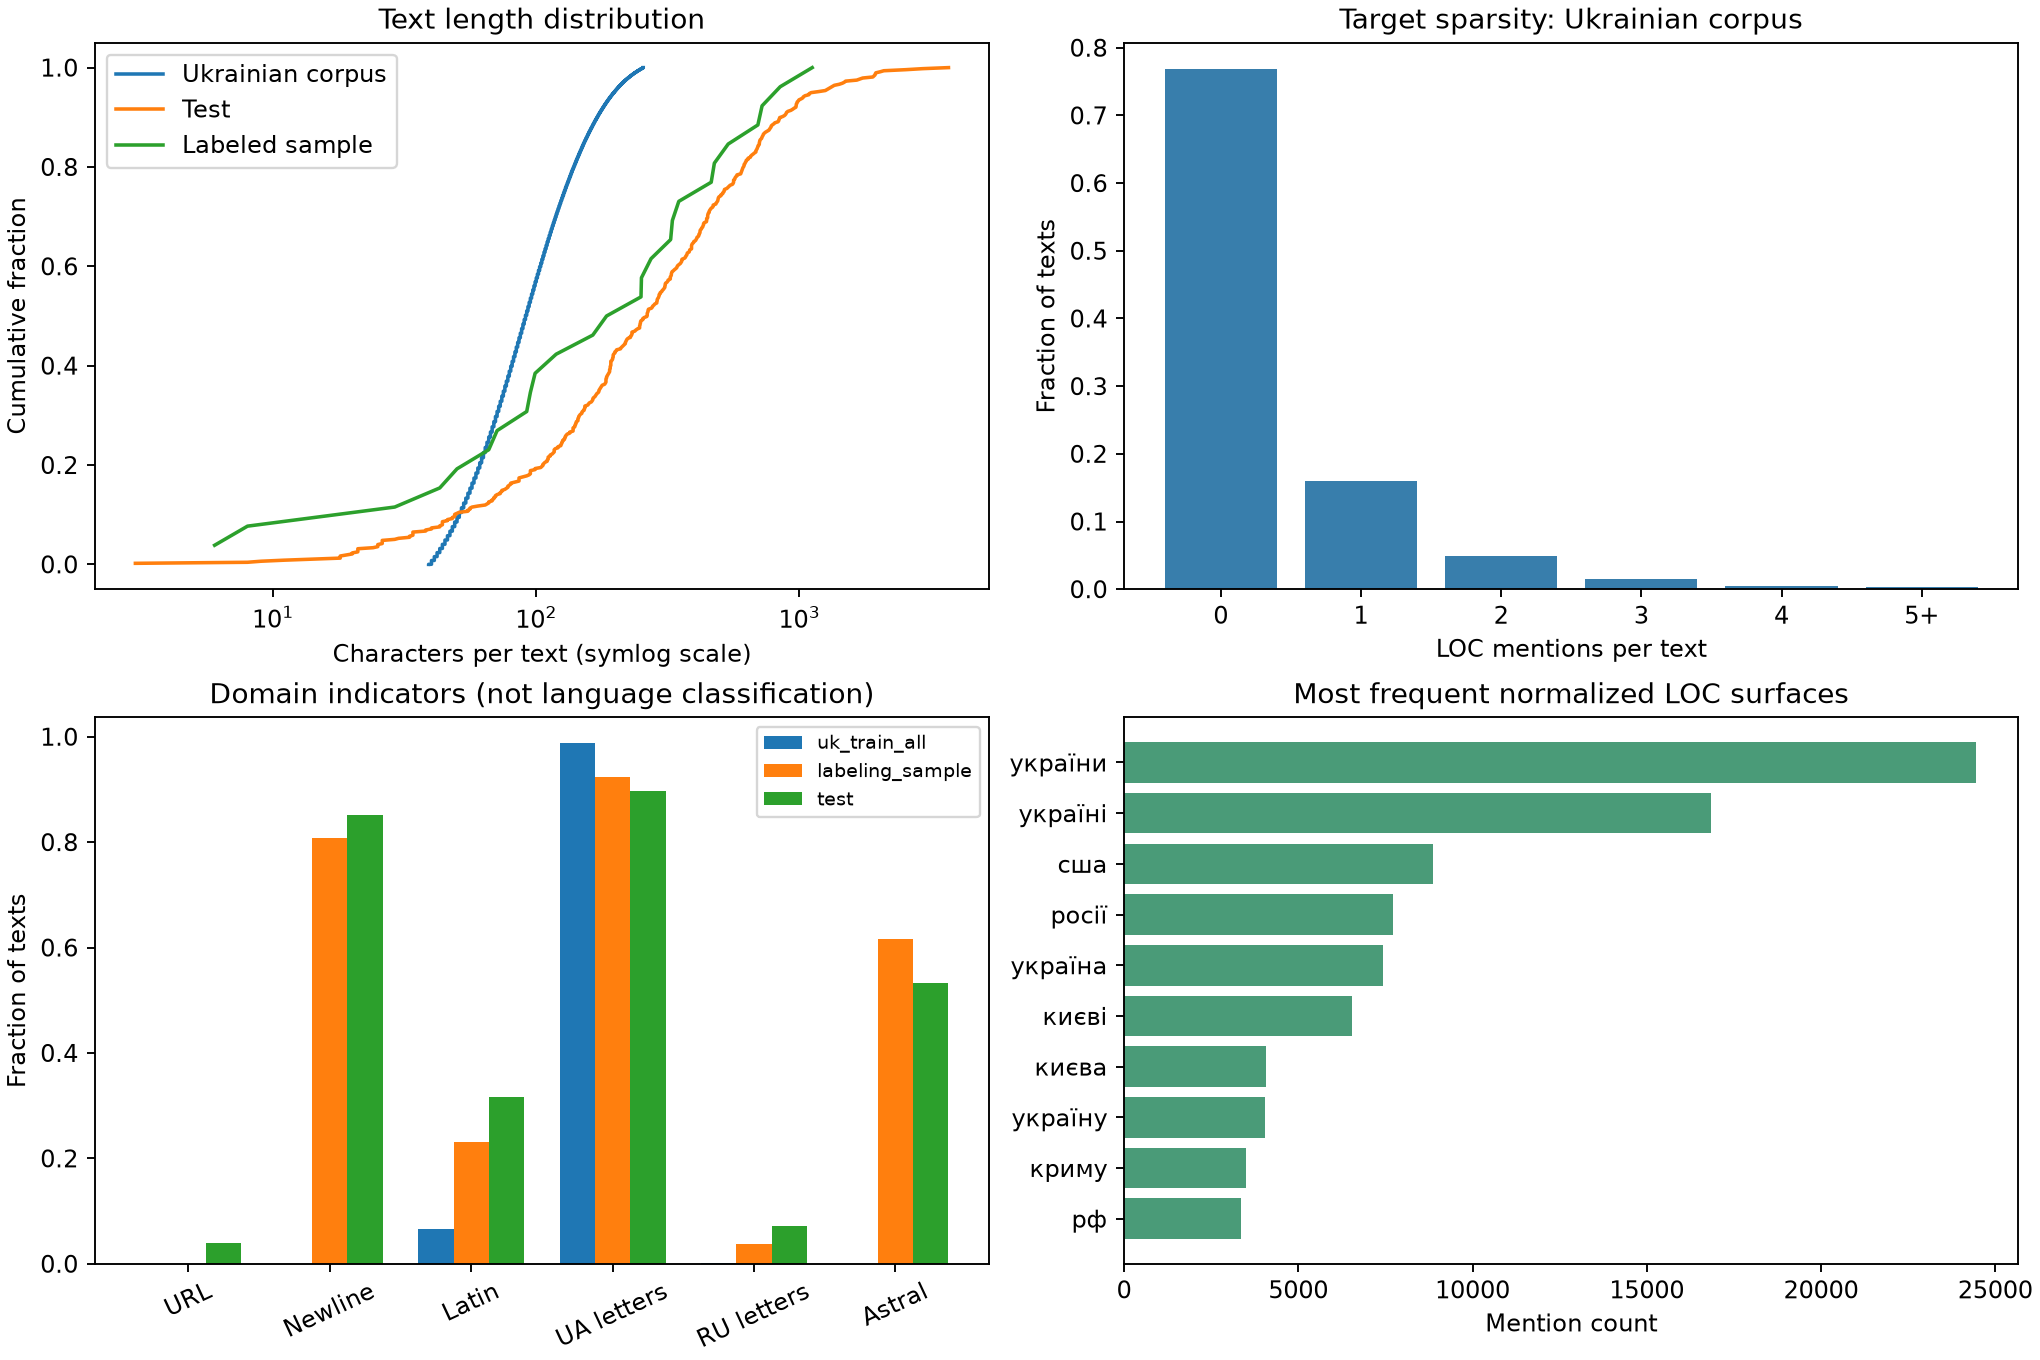

In [2]:
display(Image(filename=str(BASE / 'figures/eda_overview.png')))

## Metric edge cases

`f1` reproduces the published literal regex. `intended_f1` is a diagnostic alternative with interpolation; neither has been verified against hidden server code. These are controlled examples, not model predictions.

In [3]:
cases = pd.read_csv(BASE / 'reports/metric_edge_cases.csv')
display(cases)

,case,gold,pred,tp,fp,fn,precision,recall,f1,intended_f1
0,case,[['Київ']],[['київ']],1,0,0,1.0,1.0,1.0,1.0
1,duplicate,"[['Київ', 'Київ']]",[['Київ']],1,0,0,1.0,1.0,1.0,1.0
2,address_number,[['вул. Миру 12']],[['вул. Миру 99']],1,0,0,1.0,1.0,1.0,1.0
3,punctuation,[['Київ']],[['Київ!']],0,1,1,0.0,0.0,0.0,1.0
4,empty_normalized,[['12']],[['99']],1,0,0,1.0,1.0,1.0,1.0
5,empty_prediction,[['Київ']],[[]],0,0,1,0.0,0.0,0.0,0.0
6,all_empty,[[]],[[]],0,0,0,1.0,1.0,1.0,1.0
7,partial_name,[['Біла Церква']],[['Церква']],0,1,1,0.0,0.0,0.0,0.0
8,morphology,[['Київ']],[['Києві']],0,1,1,0.0,0.0,0.0,0.0
9,latin_regex,[['Paris']],[['Cairo']],1,0,0,1.0,1.0,1.0,0.0


In [4]:
from metrics import comp_metric, score_details, conservative_processing
gold, pred = [['вул. Миру 12']], [['вул. Миру 99']]
print('Published-code F1:', comp_metric(gold, pred))
print('Conservative alternative F1:', score_details(gold, pred, conservative_processing)['f1'])
print('Randomized parity checks:', summary['metric_parity_random_cases'])

Published-code F1: 1.0
Conservative alternative F1: 0.0
Randomized parity checks: 500


## Reproduce the full census (optional)

This cell reads all 1,010,000 raw rows and all processed rows, checks labels and duplicates, then overwrites derived artifacts. Original downloaded data are unchanged.

In [ ]:
# Uncomment to recompute from downloaded files:
# import analyze
# analyze.main()
# import build_deliverables
# build_deliverables.main()